# Capítulo 3 · Actividad: limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/02_actividad_limpieza_outliers.ipynb)

Vas a aplicar lo que viste en la notebook de clase `04_limpieza_y_outliers` a **tres datasets distintos**. Cada uno tiene problemas diferentes, igual que en la vida real.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Añade todas las celdas que necesites.
- En las celdas ✍️ **justifica tus decisiones**: en limpieza de datos casi nunca hay una única respuesta correcta, pero siempre tiene que haber un motivo.
- Al terminar, ejecuta **Kernel → Restart & Run All**.

| Parte | Datos | Tema |
|---|---|---|
| A. Empleados | una tabla pequeña creada en la notebook | Limpieza estructural e imputación |
| B. Pingüinos | `data/penguins.csv` | Valores faltantes |
| C. Viviendas de California | `data/california_housing.csv` | Outliers |

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## Parte A · Empleados 👩‍💼

Recursos Humanos te pasa esta tabla, exportada a mano de varias hojas de cálculo. Ejecuta la celda para crearla.

In [13]:
empleados = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Pedro", "Sofía", "Juan", "Elena",
               "Diego", "Carla", "Raúl", "Elena", "Iván", "Lucía"],
    "departamento": [" ventas", "IT", "it ", "IT", "Ventas", "RRHH", "rrhh", "VENTAS",
                     "It", "ventas ", "IT", "VENTAS", "RRHH", " Rrhh"],
    "edad": [34, np.nan, 29, np.nan, 45, 38, np.nan, 41, 27, np.nan, 52, 41, 31, 36],
    "salario": ["$35,000", "$52,000", "$48,500", "$52,000", "39000", "$41,200", "$37,800",
                "40500", "$47,000", "$36,900", "$61,000", "40500", "$39,900", "$42,300"],
    "fecha_ingreso": ["2019-03-15", "2020-07-01", "2021-01-10", "2020-07-01", "2015-09-30",
                      "2018-11-05", "2022-02-14", "2016-06-20", "2023-04-03", "2021-08-16",
                      "2012-01-09", "2016-06-20", "2019-10-21", "2017-05-02"],
})
empleados

,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Luis,IT,NaN,"$52,000",2020-07-01
4,Pedro,Ventas,45.0,39000,2015-09-30
5,Sofía,RRHH,38.0,"$41,200",2018-11-05
6,Juan,rrhh,NaN,"$37,800",2022-02-14
7,Elena,VENTAS,41.0,40500,2016-06-20
8,Diego,It,27.0,"$47,000",2023-04-03
9,Carla,ventas,NaN,"$36,900",2021-08-16


### Ejercicio 1 · Diagnóstico

Haz el diagnóstico de calidad de `empleados`: tipos de cada columna, valores faltantes, filas duplicadas y cómo están escritas las categorías.

In [14]:
# diagnostico de empleados
print("informacion general y tipos de datos:")
empleados.info()

print("\nvalores faltantes por columna:")
display(pd.DataFrame({
    "nulos": empleados.isna().sum(),
    "porcentaje": (empleados.isna().mean() * 100).round(1)
}))

print("\ncantidad de filas duplicadas:", empleados.duplicated().sum())

print("\nvalores unicos en departamento:")
display(empleados["departamento"].value_counts(dropna=False))

informacion general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   nombre         14 non-null     str    
 1   departamento   14 non-null     str    
 2   edad           10 non-null     float64
 3   salario        14 non-null     str    
 4   fecha_ingreso  14 non-null     str    
dtypes: float64(1), str(4)
memory usage: 692.0 bytes

valores faltantes por columna:


,nulos,porcentaje
nombre,0,0.0
departamento,0,0.0
edad,4,28.6
salario,0,0.0
fecha_ingreso,0,0.0



cantidad de filas duplicadas: 2

valores unicos en departamento:


departamento
IT         3
RRHH       2
VENTAS     2
 ventas    1
it         1
Ventas     1
rrhh       1
It         1
ventas     1
 Rrhh      1
Name: count, dtype: int64

✍️ **Pregunta:** haz una lista de todos los problemas que encontraste.

✍️ **Tu respuesta:**
los problemas encontrados en la tabla de empleados son:
1. valores faltantes: la columna edad tiene valores nulos (4 registros sin edad).
2. filas duplicadas: hay filas repetidas exactamente iguales (por ejemplo luis de it y elena de ventas).
3. texto inconsistente: en la columna departamento hay espacios en blanco adicionales al inicio y al final, y diferencias en el uso de mayusculas y minusculas (ventas, it, rrhh).
4. tipos de datos incorrectos: la columna salario contiene cadenas de texto con simbolos de pesos y comas en lugar de numeros; fecha_ingreso esta guardada como texto en lugar de formato datetime.

### Ejercicio 2 · Duplicados

Elimina las filas duplicadas. ¿Cuántas filas quedan?

In [15]:
# eliminar filas duplicadas
empleados = empleados.drop_duplicates().reset_index(drop=True)
print("filas restantes tras eliminar duplicados:", len(empleados))
display(empleados)

filas restantes tras eliminar duplicados: 12


,nombre,departamento,edad,salario,fecha_ingreso
0,Ana,ventas,34.0,"$35,000",2019-03-15
1,Luis,IT,NaN,"$52,000",2020-07-01
2,Marta,it,29.0,"$48,500",2021-01-10
3,Pedro,Ventas,45.0,39000,2015-09-30
4,Sofía,RRHH,38.0,"$41,200",2018-11-05
5,Juan,rrhh,NaN,"$37,800",2022-02-14
6,Elena,VENTAS,41.0,40500,2016-06-20
7,Diego,It,27.0,"$47,000",2023-04-03
8,Carla,ventas,NaN,"$36,900",2021-08-16
9,Raúl,IT,52.0,"$61,000",2012-01-09


### Ejercicio 3 · Texto inconsistente

Normaliza `departamento` para que queden **exactamente tres** valores: `Ventas`, `IT` y `RRHH` (las siglas, en mayúsculas).

In [16]:
# normalizar texto en la columna departamento
empleados["departamento"] = empleados["departamento"].str.strip()

# mapeo a las tres categorias requeridas
mapeo_deptos = {
    "ventas": "Ventas",
    "it": "IT",
    "rrhh": "RRHH"
}
empleados["departamento"] = empleados["departamento"].str.lower().map(mapeo_deptos)

print("valores unicos normalizados:", empleados["departamento"].unique())
display(empleados["departamento"].value_counts())

valores unicos normalizados: <StringArray>
['Ventas', 'IT', 'RRHH']
Length: 3, dtype: str


departamento
Ventas    4
IT        4
RRHH      4
Name: count, dtype: int64

### Ejercicio 4 · Tipos de datos

a) Convierte `salario` a número. Ojo: no todos los valores tienen el mismo formato.

b) Convierte `fecha_ingreso` a fecha y crea la columna `año_ingreso`.

c) Comprueba los tipos con `dtypes`.

In [17]:
# a) convertir salario a numero
empleados["salario"] = (
    empleados["salario"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)
empleados["salario"] = pd.to_numeric(empleados["salario"])

# b) convertir fecha_ingreso a fecha y extraer año_ingreso
empleados["fecha_ingreso"] = pd.to_datetime(empleados["fecha_ingreso"])
empleados["año_ingreso"] = empleados["fecha_ingreso"].dt.year

# c) comprobar tipos de datos
print("tipos de datos comprobados:")
display(empleados.dtypes)
display(empleados)

tipos de datos comprobados:


nombre                      str
departamento                str
edad                    float64
salario                   int64
fecha_ingreso    datetime64[us]
año_ingreso               int32
dtype: object

,nombre,departamento,edad,salario,fecha_ingreso,año_ingreso
0,Ana,Ventas,34.0,35000,2019-03-15,2019
1,Luis,IT,NaN,52000,2020-07-01,2020
2,Marta,IT,29.0,48500,2021-01-10,2021
3,Pedro,Ventas,45.0,39000,2015-09-30,2015
4,Sofía,RRHH,38.0,41200,2018-11-05,2018
5,Juan,RRHH,NaN,37800,2022-02-14,2022
6,Elena,Ventas,41.0,40500,2016-06-20,2016
7,Diego,IT,27.0,47000,2023-04-03,2023
8,Carla,Ventas,NaN,36900,2021-08-16,2021
9,Raúl,IT,52.0,61000,2012-01-09,2012


### Ejercicio 5 · Imputación

a) Crea una columna `edad_faltante` que indique qué empleados no tenían la edad.

b) Rellena la edad con la **mediana de su departamento**.

c) Comprueba que ya no quedan nulos y muestra la tabla final.

In [18]:
# a) crear columna indicadora de edad faltante
empleados["edad_faltante"] = empleados["edad"].isna().astype(int)

# b) rellenar edad con la mediana de cada departamento
mediana_depto = empleados.groupby("departamento")["edad"].transform("median")
empleados["edad"] = empleados["edad"].fillna(mediana_depto)

# c) comprobar que ya no quedan nulos y mostrar la tabla final
print("valores nulos restantes:", empleados.isna().sum().sum())
display(empleados)

valores nulos restantes: 0


,nombre,departamento,edad,salario,fecha_ingreso,año_ingreso,edad_faltante
0,Ana,Ventas,34.0,35000,2019-03-15,2019,0
1,Luis,IT,29.0,52000,2020-07-01,2020,1
2,Marta,IT,29.0,48500,2021-01-10,2021,0
3,Pedro,Ventas,45.0,39000,2015-09-30,2015,0
4,Sofía,RRHH,38.0,41200,2018-11-05,2018,0
5,Juan,RRHH,36.0,37800,2022-02-14,2022,1
6,Elena,Ventas,41.0,40500,2016-06-20,2016,0
7,Diego,IT,27.0,47000,2023-04-03,2023,0
8,Carla,Ventas,41.0,36900,2021-08-16,2021,1
9,Raúl,IT,52.0,61000,2012-01-09,2012,0


✍️ **Pregunta:** ¿por qué la mediana del departamento y no la mediana de todos los empleados? ¿En qué caso daría igual?

✍️ **Tu respuesta:**
se usa la mediana del departamento porque cada area suele tener caracteristicas y rangos de edad particulares (por ejemplo, perfiles mas jovenes en ciertas areas o mas experimentados en otras); imputar por grupo respeta mejor la realidad de cada sector de la empresa.

daria exactamente igual si la mediana de edad fuera la misma en todos los departamentos, o si no existiera ninguna relacion o diferencia de edad entre areas.

---
## Parte B · Pingüinos 🐧 (valores faltantes)

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies. Columnas: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` y `sex`.

### Ejercicio 6 · Diagnóstico de faltantes

a) Carga los datos en `pinguinos`.

b) Calcula cuántos valores faltan en cada columna y qué porcentaje representan.

c) Muestra las filas que tienen algún valor faltante.

In [19]:
# a) cargar el dataset de pinguinos
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")

# b) calcular faltantes y porcentaje por columna
faltantes_pinguinos = pd.DataFrame({
    "nulos": pinguinos.isna().sum(),
    "porcentaje": (pinguinos.isna().mean() * 100).round(2)
})
display(faltantes_pinguinos)

# c) mostrar filas con algun valor faltante
filas_con_nulos = pinguinos[pinguinos.isna().any(axis=1)]
print("total de filas con faltantes:", len(filas_con_nulos))
display(filas_con_nulos)

,nulos,porcentaje
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


total de filas con faltantes: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


✍️ **Pregunta:** ¿ves algún patrón en las filas con faltantes? ¿Faltan los datos de forma parecida en todas?

✍️ **Tu respuesta:**
si, se observa un patron claro:
1. hay dos filas (indices 3 y 339) a las que les faltan todas las medidas morfologicas (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g) y tambien el sexo.
2. en las restantes filas con datos faltantes, todas las medidas fisicas numericas estan completas y solo falta registrar la variable sexo.
no faltan de forma parecida en todas: dos individuos tienen ausencia total de mediciones y el resto solo carece del sexo.

### Ejercicio 7 · Eliminar o imputar

Hay pingüinos a los que les faltan **todas** las medidas. Elimínalos y comprueba cuántas filas quedan.

In [20]:
# eliminar pinguinos sin ninguna medida
columnas_medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
pinguinos = pinguinos.dropna(subset=columnas_medidas, how="all").reset_index(drop=True)
print("filas restantes tras eliminar registros vacios:", len(pinguinos))
display(pinguinos.isna().sum())

filas restantes tras eliminar registros vacios: 342


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64

✍️ **Pregunta:** ¿por qué en este caso es mejor eliminar esas filas que imputarlas?

✍️ **Tu respuesta:**
es mejor eliminarlas porque no contienen ninguna informacion biologica real del individuo. intentar imputar todas las dimensiones corporales (pico, aletas, peso) implicaria inventar un pinguino artificial completo solo a partir de su especie e isla, lo que alteraria las correlaciones naturales entre variables. ademas, solo representan 2 filas de 344 (menos del 1% del dataset), por lo que removerlas no perjudica la muestra.

### Ejercicio 8 · Dos estrategias para el sexo

Compara dos formas de rellenar `sex`, cada una en una **copia** de `pinguinos`:

a) Con la **moda**.

b) Con una categoría nueva, `"desconocido"`.

Muestra `value_counts()` del resultado en cada caso.

In [21]:
# a) copia rellenando con la moda
pinguinos_moda = pinguinos.copy()
moda_sex = pinguinos_moda["sex"].mode()[0]
pinguinos_moda["sex"] = pinguinos_moda["sex"].fillna(moda_sex)
print("frecuencias tras imputar con la moda:")
display(pinguinos_moda["sex"].value_counts(dropna=False))

# b) copia rellenando con 'desconocido'
pinguinos_desconocido = pinguinos.copy()
pinguinos_desconocido["sex"] = pinguinos_desconocido["sex"].fillna("desconocido")
print("\nfrecuencias tras imputar con 'desconocido':")
display(pinguinos_desconocido["sex"].value_counts(dropna=False))

frecuencias tras imputar con la moda:


sex
Male      177
Female    165
Name: count, dtype: int64


frecuencias tras imputar con 'desconocido':


sex
Male           168
Female         165
desconocido      9
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué estrategia elegirías aquí y por qué? Fíjate en cuántos machos y hembras hay.

✍️ **Tu respuesta:**
elegiria la estrategia de crear la categoria 'desconocido'. la razon es que la distribucion entre machos y hembras en el dataset esta practicamente balanceada (168 machos frente a 165 hembras). imputar los faltantes con la moda añadiria todos los casos a una sola categoria y crearia un sesgo artificial hacia el sexo mayoritario sin sustento real.

### Ejercicio 9 · Con scikit-learn

Usa `SimpleImputer` para rellenar `sex` con el valor más frecuente. ¿Qué valor aprendió? ¿Coincide con la moda del ejercicio 8?

In [22]:
# imputacion con simpleimputer
imputador_sexo = SimpleImputer(strategy="most_frequent")
imputador_sexo.fit(pinguinos[["sex"]])

valor_aprendido = imputador_sexo.statistics_[0]
print("valor aprendido por simpleimputer:", valor_aprendido)
print("coincide con la moda calculada anteriormente?:", valor_aprendido == moda_sex)

valor aprendido por simpleimputer: Male
coincide con la moda calculada anteriormente?: True


---
## Parte C · Viviendas de California 🏠 (outliers)

El archivo `data/california_housing.csv` viene del censo de California de 1990. **Cada fila es un distrito** (un barrio), no una vivienda:

| Columna | Significado |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de $) |
| `HouseAge` | antigüedad mediana de las viviendas (años) |
| `AveRooms` | número medio de habitaciones por vivienda |
| `AveBedrms` | número medio de dormitorios por vivienda |
| `Population` | población del distrito |
| `AveOccup` | número medio de personas por vivienda |
| `Latitude`, `Longitude` | ubicación |
| `MedHouseVal` | valor mediano de las viviendas (en cientos de miles de $) |

### Ejercicio 10 · Primer vistazo

Carga los datos en `california` y muestra sus estadísticas descriptivas.

In [23]:
# cargar california y mostrar estadisticas descriptivas
california = pd.read_csv(DATA_DIR / "california_housing.csv")
display(california.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


✍️ **Pregunta:** ¿en qué columnas el máximo está muy lejos del percentil 75%? ¿Te parece posible algún valor?

✍️ **Tu respuesta:**
las columnas con valores maximos desproporcionadamente alejados del percentil 75% son:
- averooms: el percentil 75% es aprox. 6 habitaciones, pero el maximo llega a casi 142 habitaciones promedio.
- aveoccup: el percentil 75% es aprox. 3.28 personas por vivienda, mientras que el maximo alcanza 1243 personas en promedio.
- avebedrms: el percentil 75% es 1.1 dormitorios, mientras el maximo es de 34 dormitorios.
- population: el percentil 75% es 1725 habitantes, y el maximo supera los 35,000 habitantes.

un promedio de 1243 personas por vivienda o 142 habitaciones por hogar en un distrito es imposible para viviendas normales, tratandose claramente de anomalías o errores de captura. una poblacion de 35,000 podria llegar a ser posible en un distrito excepcionalmente extenso o denso, pero sigue siendo un caso muy extremo.

### Ejercicio 11 · Detección visual

Dibuja en una misma figura el boxplot de `AveRooms`, `AveOccup` y `Population`, cada uno en su propio gráfico.

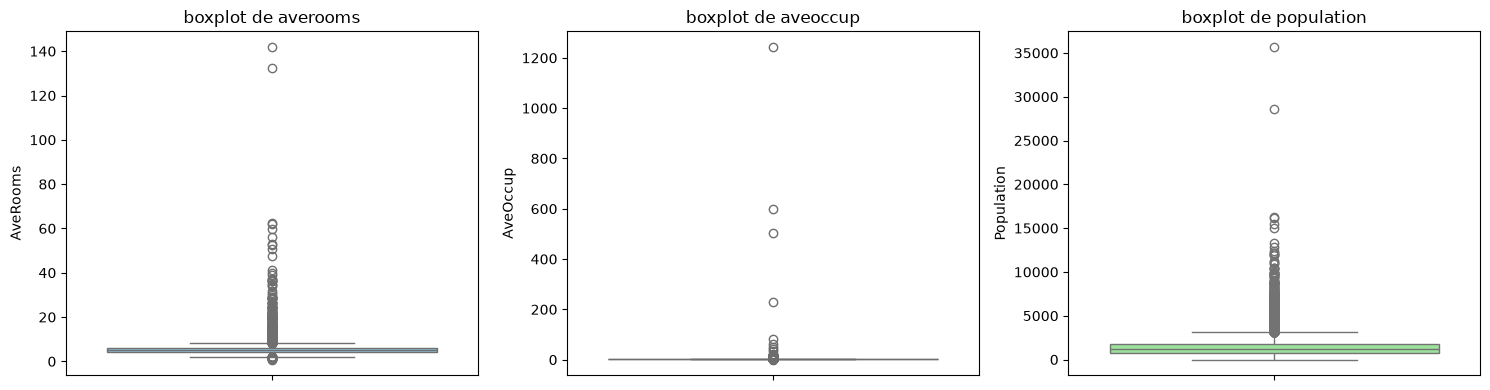

In [24]:
# visualizacion de boxplots para averooms, aveoccup y population
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=california["AveRooms"], ax=axes[0], color="skyblue")
axes[0].set_title("boxplot de averooms")

sns.boxplot(y=california["AveOccup"], ax=axes[1], color="salmon")
axes[1].set_title("boxplot de aveoccup")

sns.boxplot(y=california["Population"], ax=axes[2], color="lightgreen")
axes[2].set_title("boxplot de population")

plt.tight_layout()
plt.show()

### Ejercicio 12 · Z-score contra IQR

Para **cada columna** de `california`, cuenta cuántos outliers detecta el z-score ($|z| > 3$) y cuántos el IQR. Junta los resultados en un DataFrame con una fila por columna.

In [25]:
# funciones para deteccion de outliers
def contar_outliers_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    inf = q1 - k * iqr
    sup = q3 + k * iqr
    return ((serie < inf) | (serie > sup)).sum()

def contar_outliers_zscore(serie, umbral=3):
    z = (serie - serie.mean()) / serie.std()
    return (z.abs() > umbral).sum()

tabla_outliers = []
for columna in california.columns:
    if pd.api.types.is_numeric_dtype(california[columna]):
        tabla_outliers.append({
            "columna": columna,
            "outliers_zscore": contar_outliers_zscore(california[columna]),
            "outliers_iqr": contar_outliers_iqr(california[columna])
        })

df_outliers = pd.DataFrame(tabla_outliers).set_index("columna")
display(df_outliers)

,outliers_zscore,outliers_iqr
columna,,
MedInc,345,681
HouseAge,0,0
AveRooms,133,511
AveBedrms,145,1424
Population,342,1196
AveOccup,8,711
Latitude,0,0
Longitude,0,0
MedHouseVal,0,1071


✍️ **Pregunta:** en `AveOccup`, ¿por qué el z-score detecta tan pocos outliers y el IQR tantos? ¿Cuál de los dos números te parece más razonable?

✍️ **Tu respuesta:**
el z-score detecta muy pocos outliers en aveoccup debido a que utiliza la media y la desviacion estandar. cuando existen valores extremos gigantescos (como 1243 personas por hogar), la desviacion estandar se dispara y se infla enormemente; esto hace que la mayoria de los valores atipicos queden camuflados dentro de los 3 desvios estandar (efecto conocido como enmascaramiento).

el metodo iqr es mucho mas robusto porque se basa en cuartiles (q1 y q3), los cuales no se ven afectados por magnitudes extremas. por este motivo, el numero reportado por el iqr es mucho mas razonable y confiable para identificar observaciones anormales.

### Ejercicio 13 · Criterio de negocio

`AveOccup` es el número medio de personas que viven en cada vivienda del distrito.

a) Muestra los 5 distritos con mayor `AveOccup`.

b) Decide un **umbral razonable** por encima del cual el valor no tiene sentido, y elimina esos distritos. ¿Cuántos eliminaste?

In [26]:
# a) mostrar los 5 distritos con mayor aveoccup
top_ocupacion = california.nlargest(5, "AveOccup")[["AveOccup", "MedInc", "Population", "AveRooms", "MedHouseVal"]]
print("los 5 distritos con mayor aveoccup:")
display(top_ocupacion)

# b) definir umbral de negocio y filtrar distritos
# un promedio superior a 10 personas por vivienda no tiene sentido residencial tipico
umbral_ocupacion = 10
distritos_anomalos = california["AveOccup"] > umbral_ocupacion
cantidad_eliminados = distritos_anomalos.sum()

california = california[~distritos_anomalos].reset_index(drop=True)
print(f"distritos eliminados con aveoccup > {umbral_ocupacion}: {cantidad_eliminados}")
print(f"filas restantes en california: {len(california)}")

los 5 distritos con mayor aveoccup:


,AveOccup,MedInc,Population,AveRooms,MedHouseVal
19006,1243.333333,10.2264,7460.0,3.166667,1.375
3364,599.714286,5.5179,4198.0,5.142857,0.675
16669,502.461538,4.2639,6532.0,9.076923,3.500
13034,230.172414,6.1359,6675.0,8.275862,2.250
9172,83.171429,4.2391,8733.0,5.123810,1.546


distritos eliminados con aveoccup > 10: 37
filas restantes en california: 20603


✍️ **Pregunta:** ¿qué umbral elegiste y por qué?

✍️ **Tu respuesta:**
se eligio un umbral de 10 personas promedio por vivienda. en distritos residenciales de california un promedio por encima de 10 personas en cada hogar representa una situacion completamente irreal para viviendas familiares estandar, reflejando errores en el registro censal o distritos especiales sin proposito residencial normal. con este umbral se descartan 37 observaciones atipicas extremas sin recortar datos viables.

### Ejercicio 14 · Winsorización

Winsoriza `AveRooms` en los percentiles 1 y 99, guardando el resultado en una columna nueva `AveRooms_wins`. Compara las estadísticas descriptivas de las dos columnas.

In [27]:
# winsorizar averooms entre percentiles 1 y 99
p01, p99 = california["AveRooms"].quantile([0.01, 0.99])
print(f"percentil 1: {p01:.2f} | percentil 99: {p99:.2f}")

california["AveRooms_wins"] = california["AveRooms"].clip(lower=p01, upper=p99)

# comparar estadisticas descriptivas
display(california[["AveRooms", "AveRooms_wins"]].describe().round(2))

percentil 1: 2.60 | percentil 99: 10.34


,AveRooms,AveRooms_wins
count,20603.00,20603.00
mean,5.43,5.33
std,2.47,1.32
min,0.85,2.60
25%,4.44,4.44
50%,5.23,5.23
75%,6.05,6.05
max,141.91,10.34


### Ejercicio 15 · Un caso raro

Muestra los 5 valores más frecuentes de `MedHouseVal`.

In [28]:
# mostrar los 5 valores mas frecuentes de medhouseval
print("top 5 valores mas frecuentes de medhouseval:")
display(california["MedHouseVal"].value_counts().head(5))

top 5 valores mas frecuentes de medhouseval:


MedHouseVal
5.00001    961
1.37500    119
1.62500    112
1.12500    103
1.87500     93
Name: count, dtype: int64

✍️ **Pregunta:** ¿qué crees que pasó con el valor más repetido? ¿Es un outlier? ¿Qué problema podría causarle a un modelo que intente predecir el valor de las viviendas?

✍️ **Tu respuesta:**
el valor mas repetido es exactamente 5.00001 (que corresponde a 500,001 dolares), apareciendo casi mil veces. esto ocurrio debido a una censura o tope superior en la recoleccion de los datos: el censo asigno un valor fijo limite a todas las viviendas que costaban 500,000 dolares o mas.

no es un outlier tradicional ni un error de dedo, sino una variable artificialmente truncada por la derecha.

el problema para un modelo predictivo es que la relacion lineal o no lineal se aplana artificialmente en el extremo superior. el modelo no podra distinguir entre viviendas de 600,000 dolares y viviendas de 2 millones, aprendiendo un limite artificial y produciendo predicciones sesgadas y subestimadas para propiedades de alto valor.